# 01 — Ingestão e Limpeza

Pipeline de ingestão dos dados meteorológicos do INMET.

**Entrada:** 16 arquivos CSV das estações automáticas do Ceará (2010–2024)  
**Saída:** `data/processed/climate_mensal.parquet` — série temporal mensal agregada

**Etapas:**
1. Leitura dos CSVs com extração de metadata (nome, código, coordenadas)
2. Limpeza e renomeação de colunas
3. Conversão de datetime e set_index
4. Agregação mensal por estação
5. Exportação em Parquet

In [1]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

In [2]:
def read_station(caminho_arquivo):
    with open(caminho_arquivo) as f:
        lines = f.readlines()

    df = pd.read_csv(caminho_arquivo, sep=';', skiprows=10)

    name_station = lines[0].split(":")[1].strip()
    station_code = lines[1].split(":")[1].strip()
    lat = lines[2].split(":")[1].strip()
    lon = lines[3].split(":")[1].strip()
    alt = lines[4].split(":")[1].strip()
    lat = float(lines[2].split(":")[1].strip())
    lon = float(lines[3].split(":")[1].strip())
    alt = float(lines[4].split(":")[1].strip())

    df['nome_estacao'] = name_station
    df['codigo'] = station_code
    df['lat'] = lat
    df['lon'] = lon
    df['altitude'] = alt

    return df

In [3]:
files = glob.glob("../data/raw/*.csv")
print(len(files))
print(files[0])
dfs = [read_station(file) for file in files]


16
../data/raw/dados_A332_H_2010-01-01_2024-12-31.csv


In [4]:
df = pd.concat(dfs, ignore_index=True)

In [5]:
estacoes = []
for file in files:
    with open(file, encoding='latin-1') as f:
        lines = f.readlines()
    estacoes.append({
        'nome': lines[0].split(':')[1].strip(),
        'codigo': lines[1].split(':')[1].strip(),
        'lat': float(lines[2].split(':')[1].strip()),
        'lon': float(lines[3].split(':')[1].strip()),
        'altitude': float(lines[4].split(':')[1].strip()),
    })

df_estacoes = pd.DataFrame(estacoes)
df_estacoes.to_parquet('../data/processed/estacoes.parquet')
print(df_estacoes)

            nome codigo       lat        lon  altitude
0    MORADA NOVA   A332 -5.091111 -38.364722     93.00
1           TAUA   A324 -6.017500 -40.281389    410.87
2      ITAPIPOCA   A359 -3.484167 -39.588611    104.49
3   GUARAMIRANGA   A314 -4.229167 -38.958889    865.53
4      JAGUARIBE   A358 -5.905556 -38.627778    149.31
5   QUIXERAMOBIM   A325 -5.174444 -39.289444    221.04
6       BARBALHA   A315 -7.300833 -39.271111    409.41
7         SOBRAL   A306 -3.748056 -40.345833     92.07
8     JAGUARUANA   A339 -4.837778 -37.699722     12.00
9      FORTALEZA   A305 -3.815833 -38.537778     29.55
10       CRATEUS   A342 -5.186667 -40.672222    298.19
11       TIANGUA   A368 -3.732222 -41.011944    756.00
12  CAMPOS SALES   A347 -7.077778 -40.362778    577.95
13        IGUATU   A319 -6.396389 -39.268889    221.56
14       QUIXADA   A369 -4.978889 -39.057222    193.00
15        ACARAU   A360 -3.121111 -40.087222     67.15


In [6]:
df = df.drop("Unnamed: 11", axis=1)

In [7]:
print(df.shape)
print(df['nome_estacao'].unique())

(1960104, 16)
['MORADA NOVA' 'TAUA' 'ITAPIPOCA' 'GUARAMIRANGA' 'JAGUARIBE'
 'QUIXERAMOBIM' 'BARBALHA' 'SOBRAL' 'JAGUARUANA' 'FORTALEZA' 'CRATEUS'
 'TIANGUA' 'CAMPOS SALES' 'IGUATU' 'QUIXADA' 'ACARAU']


In [8]:
df.head()

,Data Medicao,Hora Medicao,"PRECIPITACAO TOTAL, HORARIO(mm)",RADIACAO GLOBAL(Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)",nome_estacao,codigo,lat,lon,altitude
0,2010-01-01,0,0.0,-0.8,27.0,27.6,27.0,72.0,66.0,72.0,3.0,MORADA NOVA,A332,-5.091111,-38.364722,93.0
1,2010-01-01,100,0.0,-0.8,26.6,27.0,26.5,76.0,72.0,76.0,1.8,MORADA NOVA,A332,-5.091111,-38.364722,93.0
2,2010-01-01,200,0.0,-0.8,26.1,26.6,26.1,78.0,76.0,78.0,1.4,MORADA NOVA,A332,-5.091111,-38.364722,93.0
3,2010-01-01,300,0.0,-0.8,25.7,26.1,25.7,80.0,78.0,80.0,0.8,MORADA NOVA,A332,-5.091111,-38.364722,93.0
4,2010-01-01,400,0.0,-0.6,25.2,25.8,25.2,83.0,80.0,83.0,0.0,MORADA NOVA,A332,-5.091111,-38.364722,93.0


In [9]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1960104 entries, 0 to 1960103
Data columns (total 16 columns):
 #   Column                                       Dtype  
---  ------                                       -----  
 0   Data Medicao                                 object 
 1   Hora Medicao                                 int64  
 2   PRECIPITACAO TOTAL, HORARIO(mm)              float64
 3   RADIACAO GLOBAL(Kj/m²)                       float64
 4   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)  float64
 5   TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)    float64
 6   TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)    float64
 7   UMIDADE REL. MAX. NA HORA ANT. (AUT)(%)      float64
 8   UMIDADE REL. MIN. NA HORA ANT. (AUT)(%)      float64
 9   UMIDADE RELATIVA DO AR, HORARIA(%)           float64
 10  VENTO, VELOCIDADE HORARIA(m/s)               float64
 11  nome_estacao                                 object 
 12  codigo                                       object 
 13  lat         

None

In [10]:
print(df.isnull().sum())

Data Medicao                                        0
Hora Medicao                                        0
PRECIPITACAO TOTAL, HORARIO(mm)                546967
RADIACAO GLOBAL(Kj/m²)                         439042
TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)    428613
TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)      428848
TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)      428843
UMIDADE REL. MAX. NA HORA ANT. (AUT)(%)        475443
UMIDADE REL. MIN. NA HORA ANT. (AUT)(%)        475579
UMIDADE RELATIVA DO AR, HORARIA(%)             473278
VENTO, VELOCIDADE HORARIA(m/s)                 455688
nome_estacao                                        0
codigo                                              0
lat                                                 0
lon                                                 0
altitude                                            0
dtype: int64


In [11]:
colunas = {
    'PRECIPITACAO TOTAL, HORARIO(mm)': 'precipitacao_mm',
    'RADIACAO GLOBAL(Kj/m²)': 'radiacao_kj_m2',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)': 'temperatura_bulbo_seco_c',
    'TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C)': 'temperatura_maxima_c',
    'TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C)': 'temperatura_minima_c',
    'UMIDADE REL. MAX. NA HORA ANT. (AUT)(%)': 'umidade_relativa_maxima_percent',
    'UMIDADE REL. MIN. NA HORA ANT. (AUT)(%)': 'umidade_relativa_minima_percent',
    'UMIDADE RELATIVA DO AR, HORARIA(%)': 'umidade_relativa_percent',
    'VENTO, VELOCIDADE HORARIA(m/s)': 'vento_velocidade_m_s',
    'Data Medicao': 'data',
    'Hora Medicao': 'hora',
}
df = df.rename(columns=colunas)

print(df.columns.tolist())

['data', 'hora', 'precipitacao_mm', 'radiacao_kj_m2', 'temperatura_bulbo_seco_c', 'temperatura_maxima_c', 'temperatura_minima_c', 'umidade_relativa_maxima_percent', 'umidade_relativa_minima_percent', 'umidade_relativa_percent', 'vento_velocidade_m_s', 'nome_estacao', 'codigo', 'lat', 'lon', 'altitude']


In [12]:
df['hora'] = df['hora'].astype(str).str.zfill(4)

In [13]:
df['hora'] = df['hora'].str.slice(0, 2) + ':' + df['hora'].str.slice(2, 4)

In [14]:
df['datetime'] = pd.to_datetime(df['data'] + ' ' + df['hora'])

In [15]:
df = df.drop(['data', 'hora'], axis=1)
df = df.set_index('datetime')

In [16]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1960104 entries, 2010-01-01 00:00:00 to 2024-12-31 23:00:00
Data columns (total 14 columns):
 #   Column                           Dtype  
---  ------                           -----  
 0   precipitacao_mm                  float64
 1   radiacao_kj_m2                   float64
 2   temperatura_bulbo_seco_c         float64
 3   temperatura_maxima_c             float64
 4   temperatura_minima_c             float64
 5   umidade_relativa_maxima_percent  float64
 6   umidade_relativa_minima_percent  float64
 7   umidade_relativa_percent         float64
 8   vento_velocidade_m_s             float64
 9   nome_estacao                     object 
 10  codigo                           object 
 11  lat                              float64
 12  lon                              float64
 13  altitude                         float64
dtypes: float64(12), object(2)
memory usage: 224.3+ MB


,precipitacao_mm,radiacao_kj_m2,temperatura_bulbo_seco_c,temperatura_maxima_c,temperatura_minima_c,umidade_relativa_maxima_percent,umidade_relativa_minima_percent,umidade_relativa_percent,vento_velocidade_m_s,nome_estacao,codigo,lat,lon,altitude
datetime,,,,,,,,,,,,,,
2010-01-01 00:00:00,0.0,-0.8,27.0,27.6,27.0,72.0,66.0,72.0,3.0,MORADA NOVA,A332,-5.091111,-38.364722,93.0
2010-01-01 01:00:00,0.0,-0.8,26.6,27.0,26.5,76.0,72.0,76.0,1.8,MORADA NOVA,A332,-5.091111,-38.364722,93.0
2010-01-01 02:00:00,0.0,-0.8,26.1,26.6,26.1,78.0,76.0,78.0,1.4,MORADA NOVA,A332,-5.091111,-38.364722,93.0
2010-01-01 03:00:00,0.0,-0.8,25.7,26.1,25.7,80.0,78.0,80.0,0.8,MORADA NOVA,A332,-5.091111,-38.364722,93.0
2010-01-01 04:00:00,0.0,-0.6,25.2,25.8,25.2,83.0,80.0,83.0,0.0,MORADA NOVA,A332,-5.091111,-38.364722,93.0


In [17]:
grouper = df.groupby([pd.Grouper(freq='ME'), 'nome_estacao'])

In [18]:
df_mensal = grouper.agg({
    'precipitacao_mm': 'sum',
    'radiacao_kj_m2': 'mean',
    'temperatura_bulbo_seco_c': 'mean',
    'temperatura_maxima_c': 'mean',
    'temperatura_minima_c': 'mean',
    'umidade_relativa_maxima_percent': 'mean',
    'umidade_relativa_minima_percent': 'mean',
    'umidade_relativa_percent': 'mean',
    'vento_velocidade_m_s': 'mean'
})

In [19]:
print(df_mensal.shape)
print(df_mensal.head(10))
print(df_mensal.isnull().sum())

(2684, 9)
                         precipitacao_mm  radiacao_kj_m2  \
datetime   nome_estacao                                    
2010-01-31 ACARAU                   42.0      816.437736   
           BARBALHA                221.0      848.321698   
           CAMPOS SALES             63.6      763.976383   
           CRATEUS                  84.6      747.555121   
           FORTALEZA                53.4     1038.030795   
           GUARAMIRANGA            124.2      685.986536   
           IGUATU                    2.6     1499.954294   
           ITAPIPOCA                56.2      753.965300   
           JAGUARIBE                64.8      797.523989   
           JAGUARUANA               20.0      798.911876   

                         temperatura_bulbo_seco_c  temperatura_maxima_c  \
datetime   nome_estacao                                                   
2010-01-31 ACARAU                       27.112399             27.690431   
           BARBALHA                     25.2

In [20]:
print(df_mensal.index)

MultiIndex([('2010-01-31',       'ACARAU'),
            ('2010-01-31',     'BARBALHA'),
            ('2010-01-31', 'CAMPOS SALES'),
            ('2010-01-31',      'CRATEUS'),
            ('2010-01-31',    'FORTALEZA'),
            ('2010-01-31', 'GUARAMIRANGA'),
            ('2010-01-31',       'IGUATU'),
            ('2010-01-31',    'ITAPIPOCA'),
            ('2010-01-31',    'JAGUARIBE'),
            ('2010-01-31',   'JAGUARUANA'),
            ...
            ('2024-12-31',       'IGUATU'),
            ('2024-12-31',    'ITAPIPOCA'),
            ('2024-12-31',    'JAGUARIBE'),
            ('2024-12-31',   'JAGUARUANA'),
            ('2024-12-31',  'MORADA NOVA'),
            ('2024-12-31',      'QUIXADA'),
            ('2024-12-31', 'QUIXERAMOBIM'),
            ('2024-12-31',       'SOBRAL'),
            ('2024-12-31',         'TAUA'),
            ('2024-12-31',      'TIANGUA')],
           names=['datetime', 'nome_estacao'], length=2684)


In [21]:
# Todos os meses de Fortaleza
df_mensal.loc[(slice(None), 'FORTALEZA'), :]

,,precipitacao_mm,radiacao_kj_m2,temperatura_bulbo_seco_c,temperatura_maxima_c,temperatura_minima_c,umidade_relativa_maxima_percent,umidade_relativa_minima_percent,umidade_relativa_percent,vento_velocidade_m_s
datetime,nome_estacao,,,,,,,,,
2010-01-31,FORTALEZA,53.4,1038.030795,28.276792,28.774619,27.795601,73.385787,66.901861,70.446701,2.751438
2010-02-28,FORTALEZA,73.4,880.359314,28.558569,28.990760,28.162146,74.490313,70.312966,72.426230,2.925186
2010-03-31,FORTALEZA,39.2,927.934475,28.853961,29.391649,28.411563,72.955032,68.396146,70.822270,2.520557
2010-04-30,FORTALEZA,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-05-31,FORTALEZA,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2024-08-31,FORTALEZA,0.0,NaN,30.350000,31.800000,29.700000,52.000000,45.000000,50.000000,4.700000
2024-09-30,FORTALEZA,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-10-31,FORTALEZA,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
# Janeiro de 2010 de todas as estações
df_mensal.loc['2010-01-31']

,precipitacao_mm,radiacao_kj_m2,temperatura_bulbo_seco_c,temperatura_maxima_c,temperatura_minima_c,umidade_relativa_maxima_percent,umidade_relativa_minima_percent,umidade_relativa_percent,vento_velocidade_m_s
nome_estacao,,,,,,,,,
ACARAU,42.0,816.437736,27.112399,27.690431,26.581671,78.985175,74.142857,76.613208,3.244340
BARBALHA,221.0,848.321698,25.261456,25.898652,24.659164,79.551213,72.115903,75.897574,1.259704
CAMPOS SALES,63.6,763.976383,24.870175,25.508367,24.277733,73.392713,67.442645,70.417004,2.185560
CRATEUS,84.6,747.555121,27.418598,28.031402,26.850404,67.340970,61.761456,64.521563,1.959299
FORTALEZA,53.4,1038.030795,28.276792,28.774619,27.795601,73.385787,66.901861,70.446701,2.751438
GUARAMIRANGA,124.2,685.986536,21.704085,22.218003,21.233888,87.807867,82.524962,85.308623,3.057943
IGUATU,2.6,1499.954294,28.976731,29.454775,28.241292,71.637640,66.230337,68.271468,2.421053
ITAPIPOCA,56.2,753.965300,27.845426,28.386709,27.376899,71.427215,66.585443,69.132492,3.836909
JAGUARIBE,64.8,797.523989,28.464151,29.209299,27.825741,67.334232,60.691375,64.033693,2.630189


In [23]:
# Janeiro de 2010 só de Fortaleza
df_mensal.loc[('2010-01-31', 'FORTALEZA')]

precipitacao_mm                      53.400000
radiacao_kj_m2                     1038.030795
temperatura_bulbo_seco_c             28.276792
temperatura_maxima_c                 28.774619
temperatura_minima_c                 27.795601
umidade_relativa_maxima_percent      73.385787
umidade_relativa_minima_percent      66.901861
umidade_relativa_percent             70.446701
vento_velocidade_m_s                  2.751438
Name: (2010-01-31 00:00:00, FORTALEZA), dtype: float64

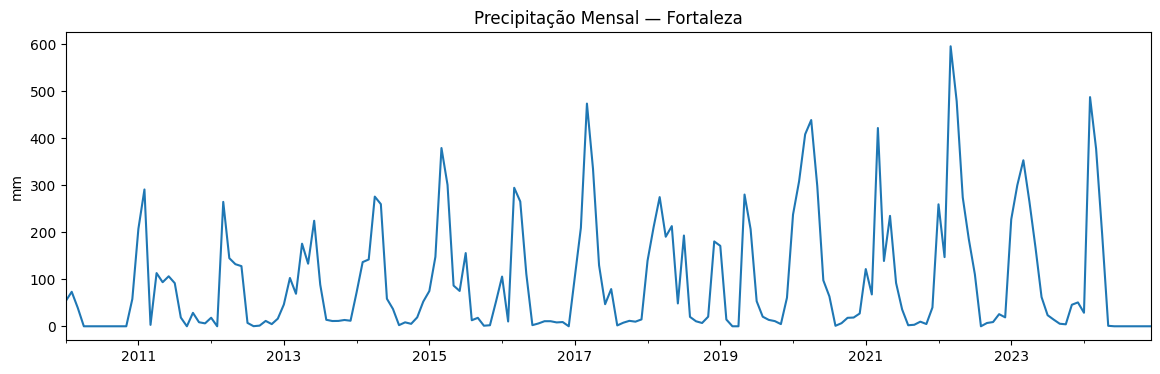

In [24]:
fortaleza = df_mensal.loc[(slice(None), 'FORTALEZA'), 'precipitacao_mm']
fortaleza.index = fortaleza.index.get_level_values('datetime')

fortaleza.plot(figsize=(14, 4), title='Precipitação Mensal — Fortaleza')
plt.ylabel('mm')
plt.xlabel('')
plt.show()

In [25]:
df_mensal.to_parquet('../data/processed/climate_mensal.parquet')

In [26]:
df_check = pd.read_parquet('../data/processed/climate_mensal.parquet')
print(df_check.dtypes)
print(df_check.shape)

precipitacao_mm                    float64
radiacao_kj_m2                     float64
temperatura_bulbo_seco_c           float64
temperatura_maxima_c               float64
temperatura_minima_c               float64
umidade_relativa_maxima_percent    float64
umidade_relativa_minima_percent    float64
umidade_relativa_percent           float64
vento_velocidade_m_s               float64
dtype: object
(2684, 9)
